# Workbook Exercise: Breast Cancer Diagnosis — An End-to-End Classification Project

**Course:** Machine Learning / Applied AI  **Level:** Intermediate  **Estimated time:** 2 hours

**Learning objectives.** By the end of this workbook you will be able to:
1. Frame a real-world problem as a supervised learning task.
2. Summarize and visualize a dataset to understand its structure before modeling.
3. Clean data, select informative features and apply appropriate transforms.
4. Build a leak-free test harness and spot-check several algorithms.
5. Improve accuracy through tuning and ensembles, then report honest test results.

**How to use this workbook.** Run the cells in order. Wherever you see `# TODO`, replace the `...` with your own code (hints are given). Cells marked ✏️ ask for a written answer: double-click to edit. Do not look at the answer key until you have tried each exercise.

**Outline**
- A. Problem Definition
- B. Summarize and Analyze Data
- C. Prepare Data
- D. Evaluate Algorithm
- E. Improve Accuracy



## Before you begin

> First, make a copy of this notebook so that you can make changes as you please.
> Run and edit the copy instead of this original notebook.

> To copy this notebook, go to `File|Save a Copy to Drive`.

**Gentle Reminder**
> Once finish, Kindly `push` this notebook to your GitHub repo.**

---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### A.2 Problem Statement
✏️ **Exercise A.1.** In 3–4 sentences, write a problem statement in your own words. Include: (a) the prediction task, (b) the input data, (c) the type of learning problem, (d) which kind of error is more costly and why, and (e) how you will judge success.

> **Your answer:This project aims to predict if a breast tumor is cancerous or non-cancerous using 30 measurements from cell nuclei. It is a supervised binary classification problem because the data already has labels for both types of tumors. A false negative is more dangerous because a cancerous tumor may be identified as non-cancerous, which can delay treatment. The model's success will be measured using accuracy, recall, and a confusion matrix to check how well it identifies cancerous tumors.


### A.3 Load Packages
**Exercise A.2.** The imports below are mostly done. Add the classifier imports you will need in Parts C–E.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, make_scorer, recall_score)

# TODO: import LogisticRegression, LinearDiscriminantAnalysis, KNeighborsClassifier, DecisionTreeClassifier, GaussianNB, SVC, RandomForest, ExtraTrees, GradientBoosting, AdaBoost and VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)

try:
    display
except NameError:
    display = print

### A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).

> *Using your own data?* Only this cell changes. For an ARFF file use `scipy.io.arff.loadarff`, and keep the rest of the workbook as is.

> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [ ]:
# TODO: load the dataset and copy its DataFrame into df
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()

print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names), "-> 0 = malignant, 1 = benign")
print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names), "-> 0 = malignant, 1 = benign")

Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign
Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign


---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [ ]:
# TODO: print the shape, the counts of each dtype, and show the first 5 rows

print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nFirst five rows:")
display(df.head())

Dataset shape: (569, 31)

Data types:
mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst concavity            float64
worst concave poi

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [ ]:
# TODO: class counts and percentages


print("Class counts:")
print(df["target"].value_counts())


print("\nClass proportions:")
print(df["target"].value_counts(normalize=True))

Class counts:
target
1    357
0    212
Name: count, dtype: int64

Class proportions:
target
1    0.627417
0    0.372583
Name: proportion, dtype: float64


**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

In [ ]:
# TODO: describe().T, then the 10 largest skewness values

display(df.describe().T)

skewness = df.drop(columns=["target"]).skew()
most_skewed = skewness.abs().sort_values(ascending=False).head(10)

print("10 most skewed features:")
print(most_skewed)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


10 most skewed features:
area error                 5.447186
concavity error            5.110463
fractal dimension error    3.923969
perimeter error            3.443615
radius error               3.088612
smoothness error           2.314450
symmetry error             2.195133
compactness error          1.902221
worst area                 1.859373
worst fractal dimension    1.662579
dtype: float64


**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [ ]:
# TODO: correlation with target, sorted

correlations = df.corr(numeric_only=True)["target"].drop("target")

print("5 Most Negative Correlations:")
print(correlations.sort_values().head(5))

print("\n5 Most Positive Correlations:")
print(correlations.sort_values(ascending=False).head(5))

5 Most Negative Correlations:
worst concave points   -0.793566
worst perimeter        -0.782914
mean concave points    -0.776614
worst radius           -0.776454
mean perimeter         -0.742636
Name: target, dtype: float64

5 Most Positive Correlations:
smoothness error           0.067016
mean fractal dimension     0.012838
texture error              0.008303
symmetry error             0.006522
fractal dimension error   -0.077972
Name: target, dtype: float64


✏️ **Question B.5.** What do the class proportions and the skewness tell you about the choice of evaluation metric and the need for transforms?

> **Your answer:The dataset has more benign cases than malignant cases, so accuracy alone is not enough to check if the model works well. We should also use recall and a confusion matrix to see if the model can correctly find cancerous tumors. Some features have uneven data, so we may need to change their values to help the model work better.

### B.2 Data Visualization

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

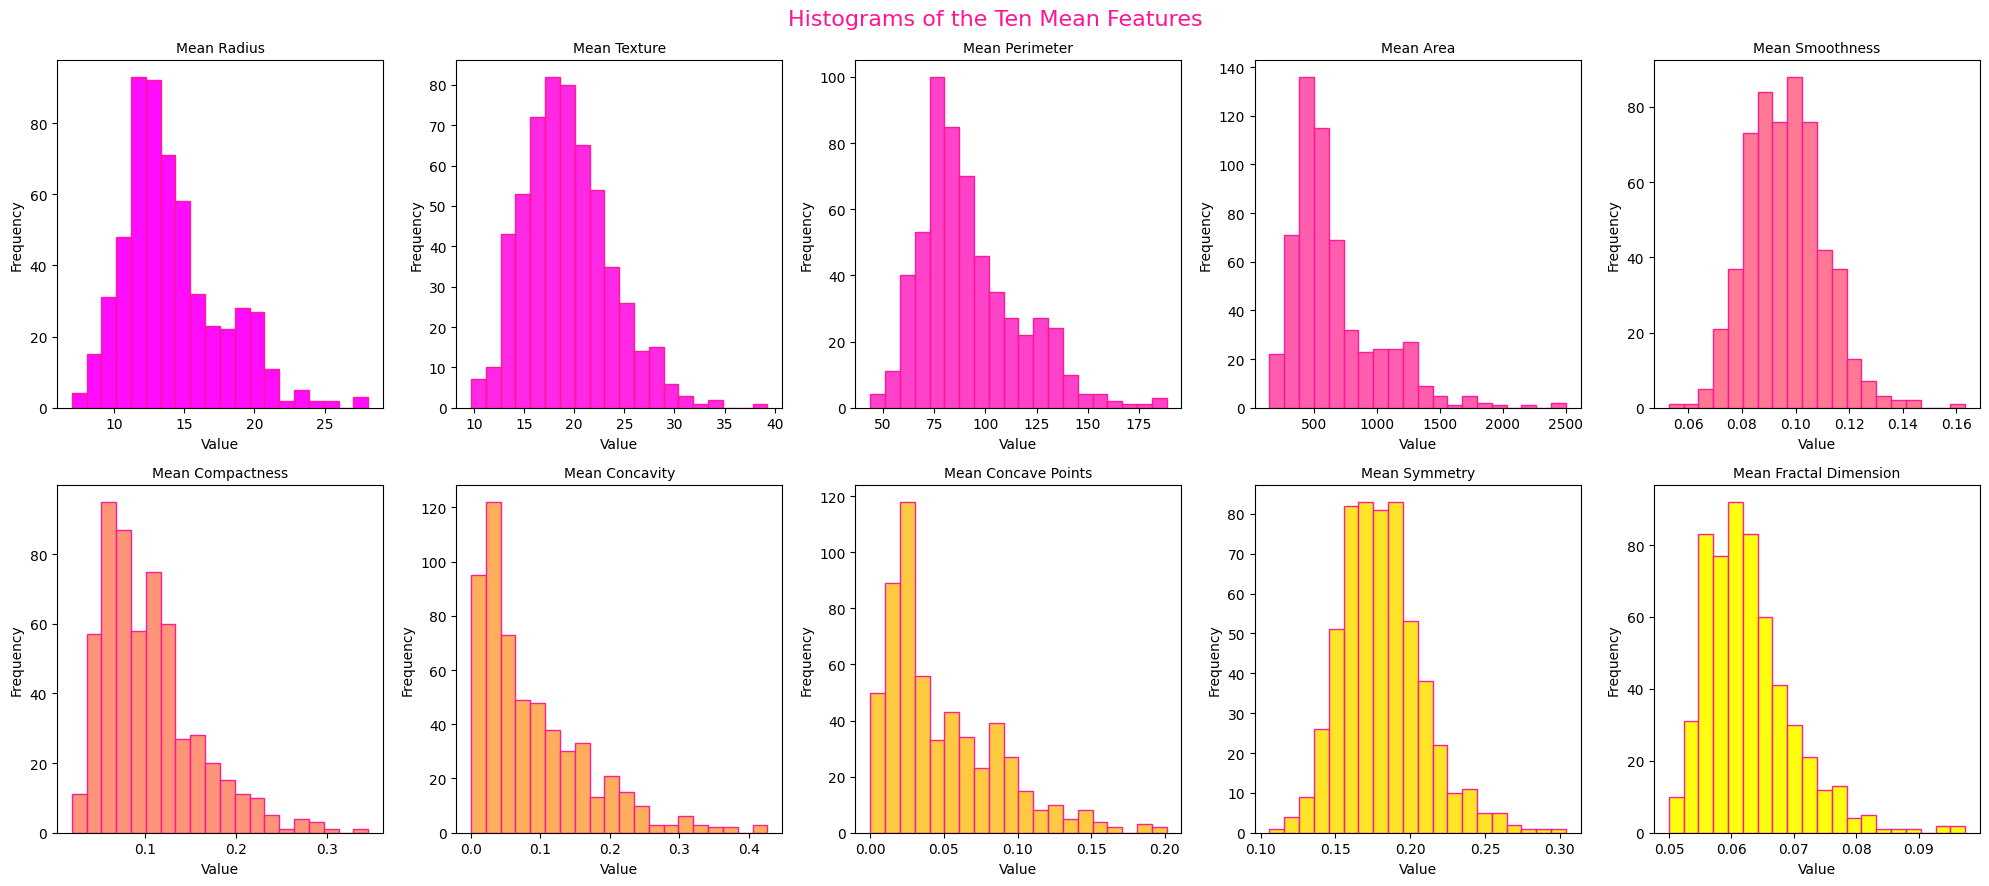

In [ ]:
# TODO: histograms of the ten "mean" features (hint: df.filter(like="mean").hist)

mean_features = [col for col in df.columns if col.startswith("mean ")]

fig, axes = plt.subplots(2, 5, figsize=(20, 9))
axes = axes.flatten()

for i, (ax, feature) in enumerate(zip(axes, mean_features)):
    spring_color = plt.cm.spring(i / (len(mean_features) - 1))

    ax.hist(
        df[feature],
        bins=20,
        color=spring_color,
        edgecolor="deeppink",
        alpha=0.95
    )

    ax.set_title(feature.title(), fontsize=10)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")

plt.suptitle("Histograms of the Ten Mean Features", fontsize=16, color="deeppink")
plt.tight_layout()
plt.show()

**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

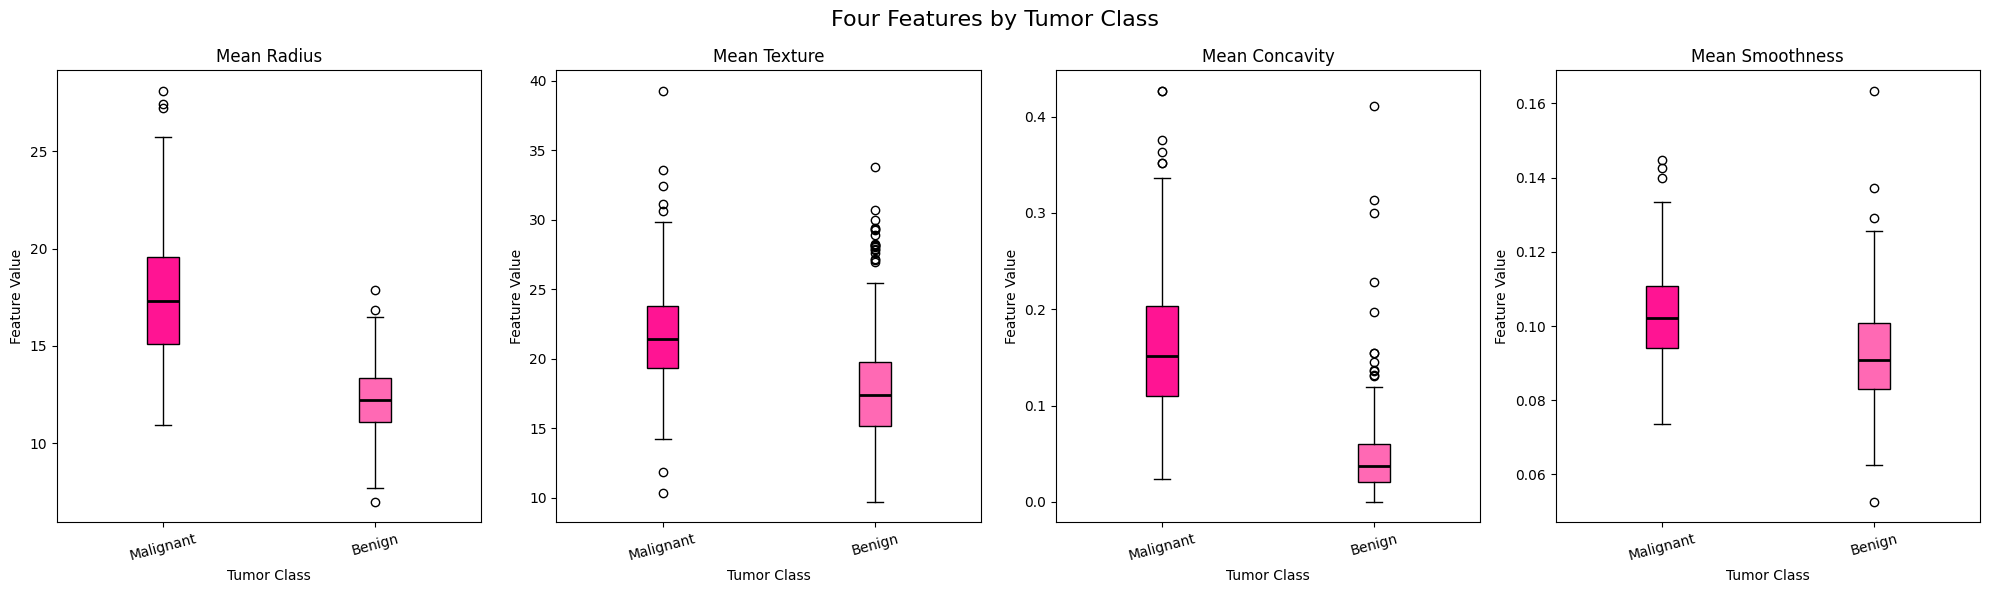

In [ ]:
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]
# TODO: one box plot per feature, grouped by target

features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]

fig, axes = plt.subplots(1, 4, figsize=(20, 6))

for ax, feature in zip(axes, features):
    data = [
        df[df["target"] == 0][feature],
        df[df["target"] == 1][feature]
    ]

    box = ax.boxplot(
        data,
        labels=["Malignant", "Benign"],
        patch_artist=True,
        medianprops=dict(color="black", linewidth=2)
    )

    colors = ["deeppink", "hotpink"]
    for patch, color in zip(box["boxes"], colors):
        patch.set_facecolor(color)

    ax.set_title(feature.title())
    ax.set_xlabel("Tumor Class")
    ax.set_ylabel("Feature Value")
    ax.tick_params(axis="x", labelrotation=15)

plt.suptitle("Four Features by Tumor Class", fontsize=16)
plt.tight_layout()
plt.show()

**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

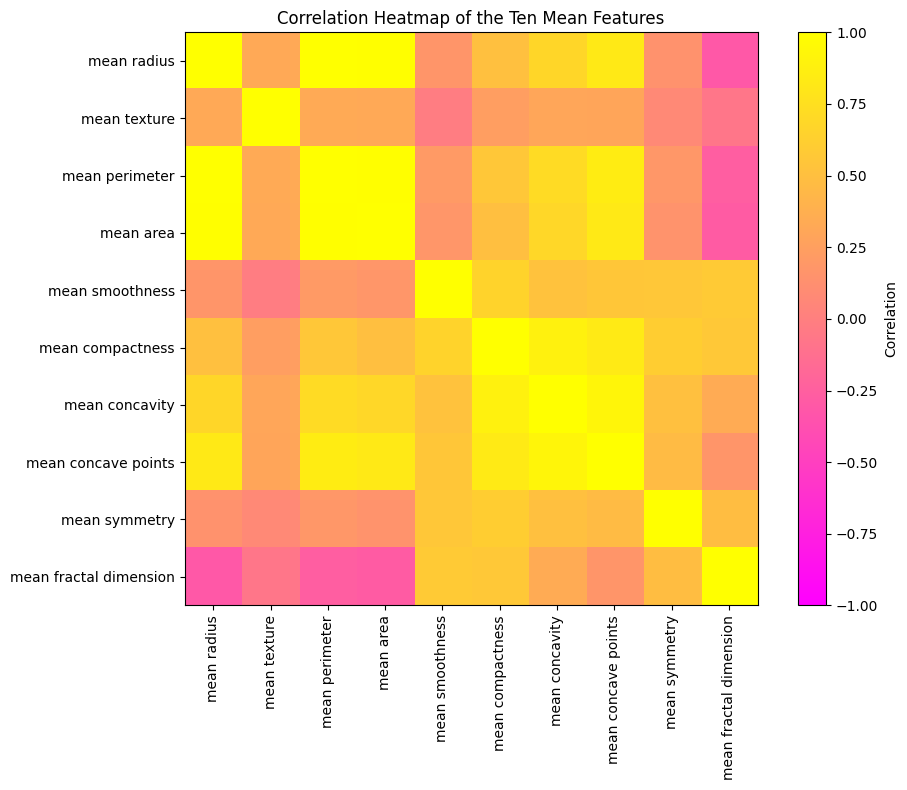

In [ ]:
# TODO: correlation matrix of the "mean" features drawn with imshow

mean_features = [col for col in df.columns if col.startswith("mean ")]

corr_matrix = df[mean_features].corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr_matrix, cmap="spring", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(mean_features)), mean_features, rotation=90)
plt.yticks(range(len(mean_features)), mean_features)
plt.title("Correlation Heatmap of the Ten Mean Features")
plt.tight_layout()
plt.show()

**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

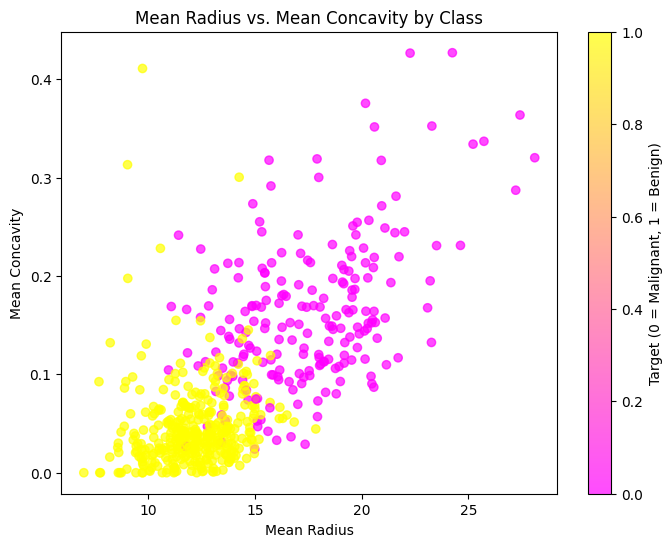

In [ ]:
# TODO: coloured scatter plot with axis labels and a colourbar

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    df["mean radius"],
    df["mean concavity"],
    c=df["target"],
    cmap="spring",
    alpha=0.7
)

plt.xlabel("Mean Radius")
plt.ylabel("Mean Concavity")
plt.title("Mean Radius vs. Mean Concavity by Class")

cbar = plt.colorbar(scatter)
cbar.set_label("Target (0 = Malignant, 1 = Benign)")

plt.show()

✏️ **Question B.10.** Which features appear redundant, and which separate the classes most clearly?

> **Your answer:Some features, like mean radius, mean perimeter, and mean area, are similar because they are related to the size of the tumor. Mean radius and mean concavity show the clearest differences between cancerous and non-cancerous tumors.

---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [ ]:
# TODO: total missing values and duplicated rows

print("Total missing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

X = df.drop(columns="target")
y = df["target"]

X = df.drop(columns="target")
y = df["target"]

Total missing values: 0
Duplicate rows: 0


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [ ]:
# TODO: IQR outlier count per feature

Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

outlier_counts = ((X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))).sum()

print("Top 10 features with the most outliers:")
print(outlier_counts.sort_values(ascending=False).head(10))

Top 10 features with the most outliers:
area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
dtype: int64


✏️ **Question C.3.** Would you delete the outlying rows? Justify your decision.

> **Your answer:No, I would not delete the outlying rows because they may contain important information about cancerous tumors. These unusual values could help the model learn the differences between malignant and benign tumors.

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [ ]:
# TODO: upper-triangle of the absolute correlation matrix, then columns above 0.95

corr_matrix = X.corr().abs()

high_corr_pairs = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
).stack()

high_corr_pairs = high_corr_pairs[high_corr_pairs > 0.95]

print("Feature pairs with absolute correlation above 0.95:")
print(high_corr_pairs)

Feature pairs with absolute correlation above 0.95:
mean radius      mean perimeter     0.997855
                 mean area          0.987357
                 worst radius       0.969539
                 worst perimeter    0.965137
mean perimeter   mean area          0.986507
                 worst radius       0.969476
                 worst perimeter    0.970387
mean area        worst radius       0.962746
                 worst perimeter    0.959120
                 worst area         0.959213
radius error     perimeter error    0.972794
                 area error         0.951830
worst radius     worst perimeter    0.993708
                 worst area         0.984015
worst perimeter  worst area         0.977578
dtype: float64


**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [ ]:
# TODO: fit SelectKBest(f_classif, k=10) and build a sorted Series of scores

selector = SelectKBest(score_func=f_classif, k=10)
selector.fit(X, y)

scores = pd.Series(selector.scores_, index=X.columns)
scores = scores.sort_values(ascending=False)

print("Top 10 features:")
print(scores.head(10))

Top 10 features:
worst concave points    964.385393
worst perimeter         897.944219
mean concave points     861.676020
worst radius            860.781707
mean perimeter          697.235272
worst area              661.600206
mean radius             646.981021
mean area               573.060747
mean concavity          533.793126
worst concavity         436.691939
dtype: float64


**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [ ]:
# TODO: RFE(LogisticRegression, n_features_to_select=10) on standardised X; store names in rfe_features

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

rfe = RFE(
    estimator=LogisticRegression(max_iter=10000),
    n_features_to_select=10
)
rfe.fit(X_scaled, y)

rfe_features = X.columns[rfe.support_].tolist()

print("Selected 10 features:")
print(rfe_features)

Selected 10 features:
['mean concave points', 'radius error', 'area error', 'compactness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

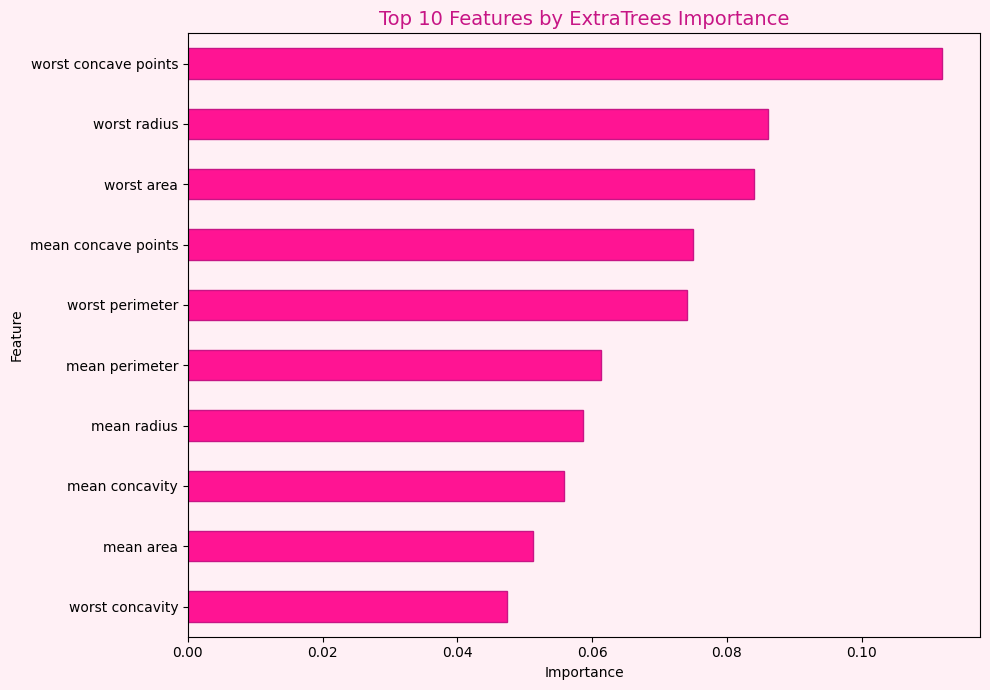

In [ ]:
# TODO: fit ExtraTrees (200 trees, random_state=7), store importances in imp, plot barh of top 10

model = ExtraTreesClassifier(n_estimators=200, random_state=7)
model.fit(X, y)

imp = pd.Series(model.feature_importances_, index=X.columns)

top10 = imp.sort_values(ascending=False).head(10).sort_values()

plt.figure(figsize=(10, 7), facecolor="#FFF0F5")
ax = top10.plot(kind="barh", color="#FF1493", edgecolor="#C71585")

ax.set_facecolor("#FFF0F5")
plt.title("Top 10 Features by ExtraTrees Importance", color="#C71585", fontsize=14)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [ ]:
# TODO: vote across the three methods

selectkbest_features = scores.head(10).index.tolist()
extratrees_features = imp.sort_values(ascending=False).head(10).index.tolist()

votes = {}

for feature in selectkbest_features + rfe_features + extratrees_features:
    votes[feature] = votes.get(feature, 0) + 1

selected = [feature for feature, count in votes.items() if count >= 2]

print("Selected features (at least 2 votes):")
print(selected)
print("Number of selected features:", len(selected))

Selected features (at least 2 votes):
['worst concave points', 'worst perimeter', 'mean concave points', 'worst radius', 'mean perimeter', 'worst area', 'mean radius', 'mean area', 'mean concavity', 'worst concavity']
Number of selected features: 10


> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [ ]:
# TODO: train_test_split with stratify=y
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=7,
    stratify=y
)

print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [ ]:
# TODO: fit both scalers on X_train and print the verifying statistics
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import pandas as pd

standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

X_train_standard = standard_scaler.fit_transform(X_train)
X_train_minmax = minmax_scaler.fit_transform(X_train)

X_train_standard_df = pd.DataFrame(
    X_train_standard, columns=X_train.columns, index=X_train.index
)
X_train_minmax_df = pd.DataFrame(
    X_train_minmax, columns=X_train.columns, index=X_train.index
)

print("StandardScaler - Mean of first four features:")
print(X_train_standard_df.iloc[:, :4].mean())

print("\nStandardScaler - Standard deviation of first four features:")
print(X_train_standard_df.iloc[:, :4].std(ddof=0))

print("\nMinMaxScaler - Minimum of first four features:")
print(X_train_minmax_df.iloc[:, :4].min())

print("\nMinMaxScaler - Maximum of first four features:")
print(X_train_minmax_df.iloc[:, :4].max())

StandardScaler - Mean of first four features:
mean radius       9.369794e-17
mean texture     -3.747918e-16
mean perimeter   -5.797560e-16
mean area        -3.279428e-16
dtype: float64

StandardScaler - Standard deviation of first four features:
mean radius       1.0
mean texture      1.0
mean perimeter    1.0
mean area         1.0
dtype: float64

MinMaxScaler - Minimum of first four features:
mean radius       0.0
mean texture      0.0
mean perimeter    0.0
mean area         0.0
dtype: float64

MinMaxScaler - Maximum of first four features:
mean radius       1.0
mean texture      1.0
mean perimeter    1.0
mean area         1.0
dtype: float64


**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

In [ ]:
# TODO: fit PCA on standardised training data and use the cumulative explained variance
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

pca = PCA()
pca.fit(X_train_scaled)

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

n_components = np.argmax(cumulative_variance >= 0.95) + 1

print("Number of principal components needed:", n_components)
print("Cumulative explained variance:", round(cumulative_variance[n_components - 1], 4))

Number of principal components needed: 10
Cumulative explained variance: 0.956


---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [ ]:
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

# TODO: dictionary named models with keys LR, LDA, KNN, CART, NB, SVM
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

models = {
    "LR": LogisticRegression(max_iter=10000, random_state=seed),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=seed),
    "NB": GaussianNB(),
    "SVM": SVC()
}

def spot_check(models, X_tr, scale):
    """Cross-validated accuracy for every model (optionally scaled inside the pipeline)."""
    results = {}
    for name, model in models.items():
        steps = ([("scale", StandardScaler())] if scale else []) + [("model", model)]
        results[name] = cross_val_score(Pipeline(steps), X_tr, y_train,
                                        cv=kfold, scoring="accuracy")
    return results

**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [ ]:
# TODO: call spot_check twice and build a DataFrame called summary with columns raw / scaled

raw_results = spot_check(models, X_train, scale=False)
scaled_results = spot_check(models, X_train, scale=True)

summary = pd.DataFrame({
    "raw": {name: scores.mean() for name, scores in raw_results.items()},
    "scaled": {name: scores.mean() for name, scores in scaled_results.items()}
})

print("Mean Accuracy of Each Model:")
display(summary.round(4))

Mean Accuracy of Each Model:


,raw,scaled
LR,0.9538,0.9823
LDA,0.9472,0.9472
KNN,0.9229,0.9649
CART,0.9276,0.9276
NB,0.9341,0.9320
SVM,0.8987,0.9758


✏️ **Question D.3.** Which models benefit from scaling, and why?

> **Your answer:KNN, SVM, and Logistic Regression usually work better with scaling because their results can be affected by differences in feature values. Scaling makes the values more balanced.

Decision Trees usually do not need scaling because they make decisions by checking values. Naive Bayes and LDA may or may not improve after scaling.

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [ ]:
# TODO: spot_check on X_train[selected] and compare against the all-features scaled results

selected_results = spot_check(models, X_train[selected], scale=True)

comparison = pd.DataFrame({
    "All Features (Scaled)": {
        name: scores.mean() for name, scores in scaled_results.items()
    },
    "Selected Features (Scaled)": {
        name: scores.mean() for name, scores in selected_results.items()
    }
})

display(comparison.round(4))

,All Features (Scaled),Selected Features (Scaled)
LR,0.9823,0.9604
LDA,0.9472,0.9430
KNN,0.9649,0.9428
CART,0.9276,0.9253
NB,0.9320,0.9517
SVM,0.9758,0.9539


**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

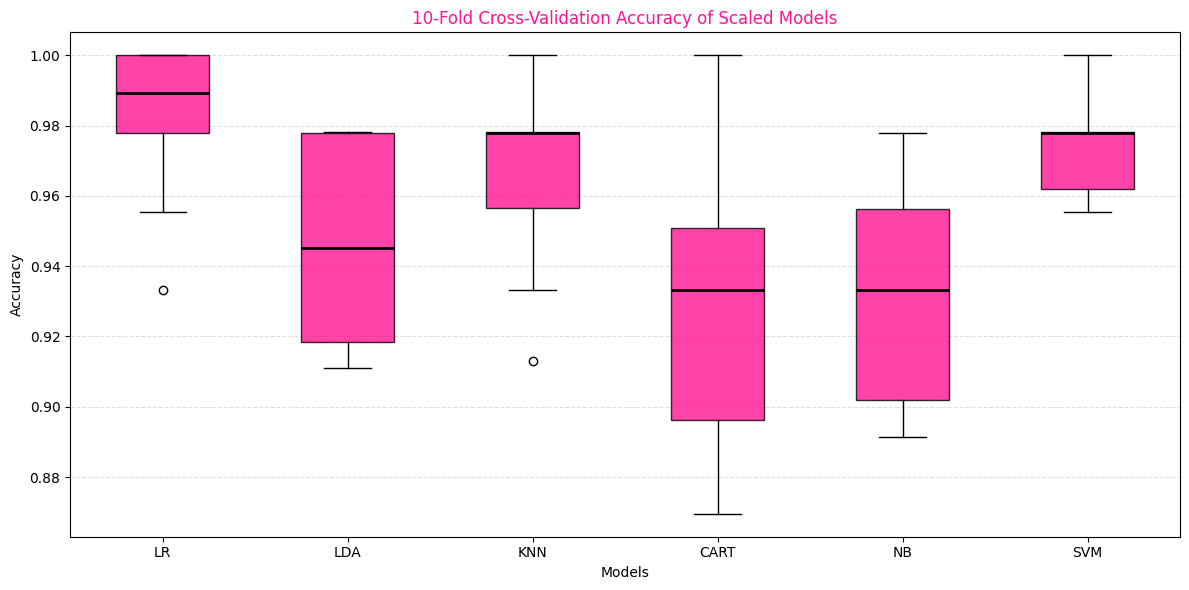

In [ ]:
# TODO: box plot of the 10 fold scores per model

plt.figure(figsize=(12, 6))

box = plt.boxplot(
    [scaled_results[name] for name in models],
    tick_labels=list(models.keys()),
    patch_artist=True
)

for patch in box["boxes"]:
    patch.set_facecolor("#FF1493")
    patch.set_alpha(0.8)

for median in box["medians"]:
    median.set_color("black")
    median.set_linewidth(2)

plt.title("10-Fold Cross-Validation Accuracy of Scaled Models", color="deeppink")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [ ]:
# TODO: cross_validate with a scoring dict including make_scorer(recall_score, pos_label=0)
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, recall_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

best_name = max(scaled_results, key=lambda name: scaled_results[name].mean())
best_model = models[best_name]

print("Best scaled model:", best_name)

scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "recall_malignant": make_scorer(recall_score, pos_label=0)
}

best_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", best_model)
])

cv_results = cross_validate(
    best_pipeline,
    X_train,
    y_train,
    cv=kfold,
    scoring=scoring
)

print("\nAverage scores across 10 folds:")
print("Accuracy:", round(cv_results["test_accuracy"].mean(), 4))
print("ROC-AUC:", round(cv_results["test_roc_auc"].mean(), 4))
print("Malignant Recall:", round(cv_results["test_recall_malignant"].mean(), 4))

Best scaled model: LR

Average scores across 10 folds:
Accuracy: 0.9823
ROC-AUC: 0.9922
Malignant Recall: 0.9647


---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [ ]:
# TODO: grid search over C=[0.1,1,10,100], gamma=["scale",0.001,0.01,0.1], kernel=["rbf","linear"]
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC())
])

param_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.001, 0.01, 0.1],
    "model__kernel": ["rbf", "linear"]
}

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=kfold,
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best cross-validation accuracy:", round(grid.best_score_, 4))

Best parameters: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best cross-validation accuracy: 0.9802


**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [ ]:
# TODO: grid over n_neighbors=[3,5,7,9,11,15,21] and weights=["uniform","distance"]
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier())
])

param_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights": ["uniform", "distance"]
}

knn_grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=kfold,
    scoring="accuracy",
    n_jobs=-1
)

knn_grid.fit(X_train, y_train)

print("Best parameters:", knn_grid.best_params_)
print("Best cross-validation accuracy:", round(knn_grid.best_score_, 4))

Best parameters: {'model__n_neighbors': 3, 'model__weights': 'uniform'}
Best cross-validation accuracy: 0.9693


### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [ ]:
# TODO: dictionary ensembles, score with spot_check(scale=False), then a hard VotingClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)

rf = RandomForestClassifier(n_estimators=200, random_state=7)

voting = VotingClassifier(
    estimators=[
        ("svm", grid.best_estimator_),
        ("knn", knn_grid.best_estimator_),
        ("rf", rf)
    ],
    voting="hard"
)

ensembles = {
    "RF": rf,
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=7),
    "Gradient Boosting": GradientBoostingClassifier(random_state=7),
    "AdaBoost": AdaBoostClassifier(random_state=7),
    "Voting": voting
}

ensemble_results = spot_check(ensembles, X_train, scale=False)

ensemble_summary = pd.DataFrame({
    "Mean Accuracy": {
        name: scores.mean()
        for name, scores in ensemble_results.items()
    }
})

display(ensemble_summary.sort_values("Mean Accuracy", ascending=False).round(4))

,Mean Accuracy
Voting,0.9781
Extra Trees,0.9714
Gradient Boosting,0.9670
RF,0.9648
AdaBoost,0.9626


**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [ ]:
# TODO: leaderboard Series

leaderboard = pd.Series({
    "Tuned SVM": grid.best_score_,
    "Tuned KNN": knn_grid.best_score_,
    "Random Forest": ensemble_results["RF"].mean(),
    "Extra Trees": ensemble_results["Extra Trees"].mean(),
    "Gradient Boosting": ensemble_results["Gradient Boosting"].mean(),
    "AdaBoost": ensemble_results["AdaBoost"].mean(),
    "Voting Ensemble": ensemble_results["Voting"].mean()
})

leaderboard = leaderboard.sort_values(ascending=False)

print("Model Leaderboard:")
display(leaderboard.round(4))

Model Leaderboard:


,0
Tuned SVM,0.9802
Voting Ensemble,0.9781
Extra Trees,0.9714
Tuned KNN,0.9693
Gradient Boosting,0.9670
Random Forest,0.9648
AdaBoost,0.9626


### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

Winning Model: Tuned SVM
Test Accuracy: 0.9649

Classification Report:
               precision    recall  f1-score   support

Malignant (0)       0.95      0.95      0.95        42
   Benign (1)       0.97      0.97      0.97        72

     accuracy                           0.96       114
    macro avg       0.96      0.96      0.96       114
 weighted avg       0.96      0.96      0.96       114



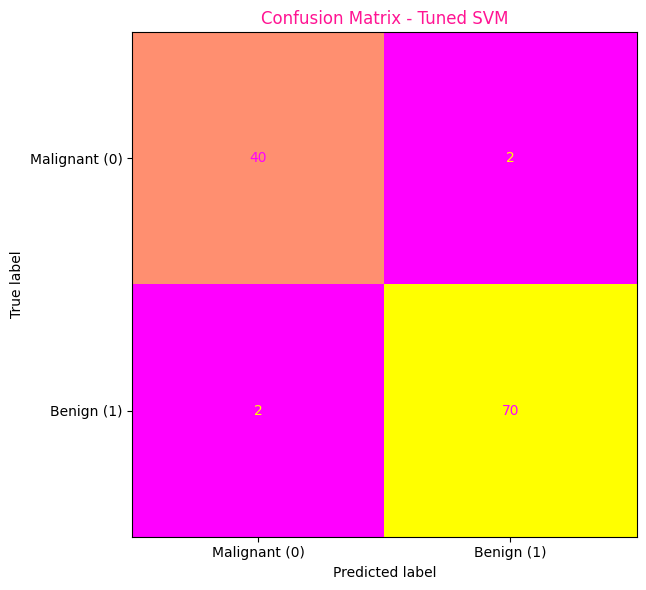

In [ ]:
# TODO: pick the leaderboard winner, fit on train, predict test, print metrics, plot confusion matrix
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

model_lookup = {
    "Tuned SVM": grid.best_estimator_,
    "Tuned KNN": knn_grid.best_estimator_,
    "Random Forest": ensembles["RF"],
    "Extra Trees": ensembles["Extra Trees"],
    "Gradient Boosting": ensembles["Gradient Boosting"],
    "AdaBoost": ensembles["AdaBoost"],
    "Voting Ensemble": ensembles["Voting"]
}

winner_name = leaderboard.index[0]
winner_model = model_lookup[winner_name]

winner_model.fit(X_train, y_train)

y_pred = winner_model.predict(X_test)

print("Winning Model:", winner_name)
print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Malignant (0)", "Benign (1)"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant (0)", "Benign (1)"]
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(
    ax=ax,
    cmap="spring",
    values_format="d",
    colorbar=False
)

plt.title(f"Confusion Matrix - {winner_name}", color="deeppink")
plt.tight_layout()
plt.show()

**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [ ]:
# TODO: joblib.dump, joblib.load, compare first 5 predictions with y_test
import joblib
import numpy as np

joblib.dump(winner_model, "best_breast_cancer_model.joblib")

loaded_model = joblib.load("best_breast_cancer_model.joblib")

loaded_pred = loaded_model.predict(X_test)

print("First 5 actual values:", y_test.iloc[:5].tolist())
print("First 5 original predictions:", y_pred[:5].tolist())
print("First 5 reloaded predictions:", loaded_pred[:5].tolist())

print("\nDo the predictions match?",
      np.array_equal(y_pred, loaded_pred))

First 5 actual values: [0, 0, 1, 0, 1]
First 5 original predictions: [0, 0, 1, 0, 1]
First 5 reloaded predictions: [0, 0, 1, 0, 1]

Do the predictions match? True


---
## Reflection Questions
✏️ Answer in a short paragraph each.

1. **Leakage.** Feature selection in Part C used the whole dataset. Explain why this can inflate CV scores and how you would fix it using a `Pipeline`.
2. **Metric choice.** Which metric would you report to a clinician, and why is accuracy alone insufficient?
3. **Model choice.** If two models differ by 0.3% in CV accuracy, how would you decide between them? (Think variance across folds, interpretability, training cost.)
4. **Generalization.** How would your conclusions change with a much smaller or much more imbalanced dataset?
5. **Extension.** Repeat the workbook with a dataset of your choice (e.g., loaded from an ARFF file) and note which steps change.

**Submission checklist:** all `TODO`s completed · all cells run top to bottom · written answers filled in · final test accuracy reported once.

Reflection Answer
1. Leakage. Using the whole dataset for feature selection can make the model's scores look better than they really are. To fix this, I would use a Pipeline so feature selection only uses the training data in each fold.

2. Metric choice. I would use malignant recall because it shows how well the model finds cancerous tumors. Accuracy is not enough because the model might get a high score but still miss some cancer cases.

3. Model choice. If the accuracy difference is only 0.3%, I would choose the model that gives more consistent results, is easier to understand, and takes less time to train.

4. Generalization. With a smaller dataset, the results may be less reliable because there is less data to learn from. If the data has many more cases of one class than the other, accuracy can be misleading. I would also check recall and the confusion matrix.

5. Extension. If I use another dataset, I need to change how I load the data and check its columns and labels. Then, I would repeat the steps for cleaning, plotting, selecting features, training, and testing the models.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%cd /content/drive/MyDrive/Colab_Notebooks/IS110_BPerformance_Jalbuena/IS110_repo_Jalbuena

/content/drive/MyDrive/Colab_Notebooks/IS110_BPerformance_Jalbuena/IS110_repo_Jalbuena


In [3]:
!git config --global user.name 'jericatheajalbuena-bit'
!git config --global user.email 'jericathea.jalbuena@students.isatu.edu.ph'

In [ ]:
!cp "/content/drive/MyDrive/Ict110_Jalbuena/Copy of ML_Workbook_Wisconsin_Diagnostic.ipynb"

In [ ]:
import os

path = '/content/drive/MyDrive'
print(os.listdir(path))

['Colab Notebooks', 'LabActivity#1- Using Google Workspace JALBUENA', 'STORYOFMYLIFETHEAA.gdoc', 'Zotero (Maravilla)jalbuena (1).gdoc', 'Classroom', 'JALBUENA-ENGLISHACTIVITY (1).gdoc', 'JALBUENA-ENGLISHACTIVITY.gdoc', 'Zotero (Maravilla)jalbuena.gdoc', 'STORY OF MY LIFE THEA.gdoc', 'Infographics_Jalbuena_BSIS1A.pdf', 'Lab Activities #5 - Excel Worksheet_JALBUENA', 'LABACT#5_EXCEL_COPY', 'PPTinEnglish_Jerica Thea Jalbuena BSIS1A_20231108_232652_0000.pptx', 'LabActivity#4 - Word_JALBUENA', 'LabActivity#5.3_Additional', 'PIVOT TABLE EXERCISE', "I am sharing 'ict103_assignment' with you", 'ict102_assignment.pdf', 'Cs1 assignment Jalbuena ', 'PracticalExcel_jalbuena', "I am sharing 'assignment 5' with you.pdf", 'Assignment #5.pdf', 'Hakdog', 'JALBUENA_HTMLCERTIFICATE.png', 'RATATYPE_JALBUENA', 'Jalbuena certificate .jpg', 'Responsive Web Design Certification(Optional)', 'Assignment #4.pdf', 'inbound5621551827537036203.jpg', 'inbound5478864812854700833.jpg', 'inbound5372576843778801155.jpg'

In [ ]:
%cd /content


/content


In [ ]:
print(os.listdir('/content/drive/MyDrive/Colab Notebooks'))

['Copy of ML_Workbook_Wisconsin_Diagnostic.ipynb']


In [ ]:
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
!ls -la /content/drive/MyDrive

total 205096
drwx------ 61 root root     4096 Oct 29 02:30  .
drwx------  5 root root     4096 Oct 29 02:30  ..
-rw-------  1 root root    86399 Mar  9  2026  01_Python_Fundamentals,_Part_1_Workbook.ipynb
-rw-------  1 root root      196 Aug 26 15:47 '113 REPORT.gdoc'
drwx------  2 root root     4096 Aug 11 05:48 '8 11 26 recordings capstone'
-rw-------  1 root root    61847 Jul  6 04:28  8ac4450e-f413-47bf-b0f1-efa0befcd8d9.jpg
drwx------  2 root root     4096 Oct 19  2025  admin
-rw-------  1 root root    14856 Oct 19  2025  admin.drawio
-rw-------  1 root root      196 Jul 24 06:50 'AFTER CONSULT KAY SIR.gdoc'
-rw-------  1 root root    16087 Jan 23  2024  ARALIN_1.docx
-rw-------  1 root root   100462 Jan 23  2024  ARALIN_2.pdf
-rw-------  1 root root    96180 Jan 23  2024  ARALIN-_3.pdf
drwx------  2 root root     4096 Dec  2  2025 'ARELLANO- SELF-CARE'
drwx------  2 root root     4096 Nov 24  2025 'Art Commercial '
-rw-------  1 root root      196 Nov 25  2025 'Art Commercial.gdo